# AI비전실무 6–7강 · 미션 01 실습
## 웨이퍼맵에서 의미 있는 특성 찾기

이 노트북은 같은 폴더의 **AIVision_6-7강_미션01_워크북.html**을 VS Code에서 실습할 수 있도록 옮긴 자료입니다.

1. 오른쪽 위 **커널 선택**에서 Python 환경을 선택하세요.
2. 아래 셀을 위에서부터 차례로 실행하세요. 실행 단축키는 **Shift+Enter**입니다.
3. 각 질문 아래의 **답변** 칸을 더블 클릭하여 기록하세요. **필수 기록** 문항을 우선 작성하세요.

입력 파일은 `LSWMD_labeled.pkl`이며, 마지막 저장 셀은 같은 폴더에 `wafer_features.pkl`을 만듭니다.


### 실행 환경 준비

필요한 패키지가 없다는 오류가 나면 다음 셀의 `%pip` 줄 앞에 있는 `#`을 지우고 한 번 실행하세요. 설치 후 필요하면 커널을 다시 시작하세요.

In [ ]:
# 필요한 경우에만 주석을 해제하여 실행하세요.
# %pip install pandas numpy matplotlib seaborn ipykernel

## 이번 미션에서 해결할 문제

지금까지 우리는 웨이퍼맵을 이미지로 변환하고, CNN을 학습시켜 불량 패턴을 분류했습니다. 데이터 증강을 적용하고, 모델이 어떤 패턴을 잘못 분류하는지도 살펴보았습니다.

그런데 이미지의 특징을 반드시 CNN이 찾아야 할까요? 사람이 웨이퍼맵을 관찰하면 불량 칩의 개수, 불량이 집중된 위치, 불량이 퍼져 있는 모양 등을 파악할 수 있습니다. 이러한 특징을 숫자로 표현하여 모델에 제공한다면 어떨까요?

**이번 미션의 핵심**

도메인 지식을 활용해 웨이퍼맵에서 의미 있는 특성을 직접 추출합니다. 이번 미션에서는 모델을 학습하지 않고, 먼저 **모델에 어떤 정보를 제공할 것인지** 생각합니다.

미션을 완료하면 다음을 할 수 있습니다.

- pickle 파일에 저장된 DataFrame을 불러오고 데이터 구조를 확인할 수 있습니다.
- 웨이퍼맵 배열에서 불량률과 가장자리 불량률을 계산할 수 있습니다.
- 추출한 특성을 DataFrame의 새로운 열로 추가할 수 있습니다.
- 불량 유형별 특성값을 비교하고 특성의 유용성을 판단할 수 있습니다.

**질문과 보고서 작성 안내**

**모든 질문의 답을 보고서에 포함할 필요는 없습니다.** 질문은 실습 중 코드를 읽고 결과를 해석하도록 돕는 장치입니다. 필수 기록이 붙은 질문은 실습 중 답을 기록해 두세요. 최종 보고서에는 마지막 「보고서에 기록할 내용」을 중심으로 정리합니다.

## 알아두기. 도메인 지식과 특성공학

### 도메인 지식(Domain Knowledge)

도메인 지식이란 특정 분야에서 사용되는 전문 지식과 경험을 의미합니다. 반도체 검사에서는 웨이퍼의 어느 위치에 불량이 발생했는지, 어떤 모양으로 분포하는지가 중요한 정보일 수 있습니다.

예를 들어 웨이퍼 전체에 불량이 흩어져 있는 경우와 가장자리를 따라 불량이 발생한 경우는 서로 다른 패턴입니다. 이때 우리는 다음과 같은 질문을 할 수 있습니다.

- 불량 칩은 전체 칩의 몇 퍼센트인가?
- 불량 칩은 웨이퍼의 어느 위치에 많은가?
- 불량 칩은 한곳에 모여 있는가, 여러 곳에 흩어져 있는가?
- 불량 칩이 선이나 원 형태의 패턴을 만드는가?

이러한 질문을 데이터의 특성으로 바꾸는 것이 이번 실습의 출발점입니다.

### 특성공학(Feature Engineering)

특성공학은 데이터에서 유용한 정보를 추출하거나 기존 정보를 변환하여 모델이 활용할 새로운 특성을 만드는 과정입니다. CNN은 이미지의 공간적 특징을 학습 과정에서 자동으로 찾아냅니다. 반면 이번 실습에서는 사람이 특성의 의미와 계산 방법을 설계합니다.

| 웨이퍼맵에서 관찰한 정보 | 숫자로 표현한 특성 |
| --- | --- |
| 불량 칩이 많다 | 전체 불량률 |
| 불량이 가장자리에 집중되어 있다 | 가장자리 불량률 |
| 불량이 위쪽에 많다 | 상단 영역 불량률 |
| 불량이 특정 위치에 모여 있다 | 불량 중심 좌표 |

이처럼 이미지에 담긴 정보를 숫자로 변환하면 일반적인 머신러닝 분류 모델에서도 활용할 수 있습니다. 다만 사람이 설계한 특성이 항상 유용한 것은 아닙니다. 실제로 분류 성능에 도움이 되는지는 이후 실험을 통해 확인해야 합니다.

ACTIVITY A

## pickle 파일을 다시 열어보자

### 1. 오랜만에 만나는 pickle

앞선 수업에서는 여러 파일에 나누어 저장된 WM-811K 데이터를 불러오고, 불필요한 데이터를 정리한 뒤 pickle 파일로 저장했습니다. pickle은 Python 객체를 파일로 저장하고 다시 불러올 수 있도록 하는 방식입니다.

이번에 사용할 파일은 `LSWMD_labeled.pkl`입니다. 라벨이 없는 데이터를 제외하고 불량 유형이 정리된 웨이퍼맵 데이터가 저장되어 있습니다. 이전에 학습했던 내용을 떠올리며 다음 코드를 실행해 보세요.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# 같은 폴더에 있는 데이터를 사용합니다.
data_dir = Path.cwd()
if not (data_dir / 'LSWMD_labeled.pkl').is_file():
    data_dir = Path('D:\\2604340036 - 송성민\\2학기\\반도체장비AI비전실무\\2026-AIVISION_06강')
file_path = data_dir / 'LSWMD_labeled.pkl'

df = pd.read_pickle(file_path)
print("불러온 파일:", file_path)
print(df.shape)  # (25519, 9)
display(df.head())

불러온 파일: d:\2604340036 - 송성민\2학기\반도체장비AI비전실무\2026-AIVISION_06강\LSWMD_labeled.pkl
(25519, 9)


,waferMap,dieSize,lotName,waferIndex,failureType,failureType_clean,waferShape,source_file,source_index
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,20.0,[[Loc]],Loc,"(45, 48)",LSWMD.pkl,19
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2460.0,lot2,12.0,[[Edge-Loc]],Edge-Loc,"(53, 58)",LSWMD.pkl,36
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2460.0,lot2,13.0,[[Edge-Loc]],Edge-Loc,"(53, 58)",LSWMD.pkl,37
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2460.0,lot2,14.0,[[Edge-Loc]],Edge-Loc,"(53, 58)",LSWMD.pkl,38
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",2460.0,lot2,15.0,[[Edge-Loc]],Edge-Loc,"(53, 58)",LSWMD.pkl,39


**코드 살펴보기**
- `pd.read_pickle()`: pickle 파일에 저장된 객체를 불러옵니다.
- `df.shape`: DataFrame의 행과 열 개수를 확인합니다.
- `df.head()`: 처음 5개 행을 확인합니다.

현재 사용 중인 데이터에는 총 **25,519개**의 웨이퍼맵이 포함되어 있습니다.

**Q1.**

`df.shape`의 출력 결과에서 첫 번째 숫자와 두 번째 숫자는 각각 무엇을 의미하나요?

**답변:**

첫 번째 숫자는 **행의 개수**, 두 번째 숫자는 **열의 개수**를 의미합니다.

**Q2.**

`waferMap` 열에는 일반적인 숫자 하나가 아니라 어떤 형태의 데이터가 저장되어 있나요?

**답변:**

각 행의 `waferMap`에는 웨이퍼의 칩 배치를 나타내는 **2차원 NumPy 배열**이 저장되어 있습니다. 각 위치의 값은 `0`이 비유효 영역, `1`이 정상 칩, `2`가 불량 칩을 의미합니다. 첫 번째 배열은 `(45, 48)` 크기의 `uint8` 배열이며, 웨이퍼에 따라 배열 크기가 다를 수 있습니다.

**Q3.**

`waferMap`과 `failureType_clean`은 이번 실습에서 각각 어떤 역할을 할까요?

**답변:**

`waferMap`은 불량 칩의 개수와 위치 등 **특성을 추출할 원본 데이터**입니다. `failureType_clean`은 `Loc`, `Edge-Ring`처럼 정리된 **불량 유형 라벨**로, 같은 유형끼리 묶어 특성값을 비교하는 기준입니다.

### 2. DataFrame의 열 다시 확인하기

In [2]:
print(df.columns.tolist())
print(df.dtypes)

display(df['failureType_clean'].value_counts())

['waferMap', 'dieSize', 'lotName', 'waferIndex', 'failureType', 'failureType_clean', 'waferShape', 'source_file', 'source_index']
waferMap              object
dieSize              float64
lotName               object
waferIndex           float64
failureType           object
failureType_clean     object
waferShape            object
source_file           object
source_index           int64
dtype: object


failureType_clean
Edge-Ring    9680
Edge-Loc     5189
Center       4294
Loc          3593
Scratch      1193
Random        866
Donut         555
Near-full     149
Name: count, dtype: int64

| 열 이름 | 의미 |
| --- | --- |
| `waferMap` | 칩의 상태를 기록한 2차원 배열 |
| `dieSize` | 유효 칩의 개수 |
| `lotName` | 제조 로트 식별 정보 |
| `waferIndex` | 로트 내 웨이퍼 번호 |
| `failureType` | 원래 불량 유형 정보 |
| `failureType_clean` | 정리된 불량 유형 |
| `waferShape` | 웨이퍼맵 배열의 크기 |
| `source_file` | 원본 데이터 파일 |
| `source_index` | 원본 파일에서의 위치 |

이번 실습에서는 `waferMap`에서 새로운 특성을 추출하고, `failureType_clean`을 이용해 불량 유형별 차이를 분석합니다.

**Q4.**

`value_counts()` 결과에서 데이터가 가장 많은 불량 유형과 가장 적은 불량 유형을 찾아보세요.

**답변:**

가장 많은 유형은 **Edge-Ring 9,680개**, 가장 적은 유형은 **Near-full 149개**입니다. 두 유형의 개수는 약 65배 차이가 나므로 데이터가 불균형합니다.

**Q5.**

불량 유형에 따라 데이터 개수가 크게 다를 때, 모델의 성능을 평가하면서 어떤 점을 주의해야 할까요? 이전 수업에서 배운 내용을 떠올려 보세요.

**답변:**

전체 정확도만 보면 데이터가 많은 유형을 잘 맞히는 모델이 좋아 보일 수 있습니다. 따라서 **유형별 정밀도·재현율·F1 점수와 혼동행렬**을 함께 확인해야 합니다. 각 유형을 같은 비중으로 반영하는 **macro F1**도 확인하고, 훈련·검증·테스트 데이터를 나눌 때는 유형별 비율과 소수 유형의 표본 수를 살펴보아야 합니다. 같은 웨이퍼나 그 증강본이 서로 다른 데이터 분할에 섞이는 데이터 누수도 주의해야 합니다.

### 3. 웨이퍼맵 배열의 구조 확인하기

DataFrame의 `waferMap` 열에는 웨이퍼맵을 구성하는 2차원 배열이 저장되어 있습니다. 이번에는 이미지를 저장하지 않고 배열을 직접 사용합니다.

In [3]:
wafer = np.asarray(df.iloc[0]['waferMap'])

print("배열 크기:", wafer.shape)
print("데이터 타입:", wafer.dtype)
print("배열에 포함된 값:", np.unique(wafer))

배열 크기: (45, 48)
데이터 타입: uint8
배열에 포함된 값: [0 1 2]


| 값 | 의미 |
| --- | --- |
| 0 | 유효하지 않은 영역 |
| 1 | 정상 칩 |
| 2 | 불량 칩 |

이제 배열을 이미지로 확인해 보겠습니다.

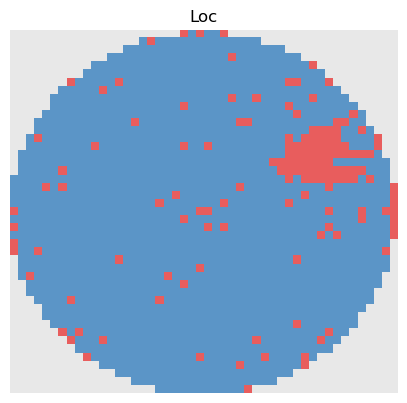

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

wafer_cmap = ListedColormap([
    '#E8E8E8',  # 0: 비유효
    '#5B95C7',  # 1: 정상
    '#E85D5D'   # 2: 불량
])

plt.figure(figsize=(5, 5))
plt.imshow(wafer, cmap=wafer_cmap, vmin=0, vmax=2)
plt.title(df.iloc[0]['failureType_clean'])
plt.axis('off')
plt.show()

이 코드는 앞선 수업의 이미지 변환 과정과 비슷합니다. 하지만 이번에는 이미지 파일로 저장하지 않고 배열의 값과 불량 위치를 분석하는 데 사용합니다.

**Q6.**

웨이퍼맵의 배열 크기와 실제 유효 칩의 개수가 항상 같을 수 없는 이유는 무엇인가요?

**답변:**

웨이퍼맵은 직사각형 배열이지만 실제 칩이 존재하지 않는 바깥 영역도 배열에 포함되어 있기 때문입니다. 배열 전체 원소 수에는 값이 `0`인 비유효 영역이 포함되지만, 유효 칩 수에는 값이 `1` 또는 `2`인 위치만 포함됩니다. 첫 번째 웨이퍼의 배열 원소는 `45 × 48 = 2,160`개이고, 유효 칩은 1,683개, 비유효 위치는 477개입니다.

**Q7.** 필수 기록

불량률을 계산할 때 배열 전체의 원소 개수를 기준으로 해야 할까요, 정상 칩과 불량 칩의 개수를 합한 값을 기준으로 해야 할까요? 이유도 설명해 보세요.

**답변:**

**정상 칩과 불량 칩의 개수를 합한 유효 칩 수**를 분모로 사용해야 합니다. 값이 `0`인 영역에는 실제 검사 대상 칩이 없으므로 불량률 계산에서 제외해야 합니다. 배열 전체를 분모로 사용하면 비유효 영역이 많을수록 불량률이 실제보다 작아집니다.

첫 번째 웨이퍼의 불량률은 `146 / 1683 ≈ 0.08675`, 즉 **약 8.67%**입니다.

ACTIVITY B

## 웨이퍼맵의 불량률 계산하기

### 1. 불량률이란?

웨이퍼맵에서 가장 쉽게 추출할 수 있는 특성은 불량률입니다. 불량률은 유효 칩 중 불량 칩이 차지하는 비율입니다.

불량률 = 불량 칩 수 ÷ (정상 칩 수 + 불량 칩 수)

예를 들어 유효 칩 1,000개 중 불량 칩이 150개라면 불량률은 0.15, 즉 15%입니다. 웨이퍼맵에서는 `np.sum()`과 조건식을 이용해 칩의 개수를 계산할 수 있습니다.

In [5]:
wafer = np.asarray(df.iloc[0]['waferMap'])

valid_count = np.sum(wafer != 0)
defect_count = np.sum(wafer == 2)

print("유효 칩 수:", valid_count)
print("불량 칩 수:", defect_count)
print("불량률:", defect_count / valid_count)

유효 칩 수: 1683
불량 칩 수: 146
불량률: 0.08674985145573381


**Q8.**

다음 두 조건식은 각각 어떤 칩을 선택하나요?
- `wafer != 0`
- `wafer == 2`

**답변:**

- `wafer != 0`: 값이 `1` 또는 `2`인 **모든 유효 칩**을 선택합니다.
- `wafer == 2`: 값이 `2`인 **불량 칩**만 선택합니다.

두 조건식의 결과는 각 위치가 조건을 만족하는지를 나타내는 불리언 배열입니다.

**Q9.**

`np.sum(wafer == 2)`가 불량 칩의 개수를 계산할 수 있는 이유를 설명해 보세요.

**답변:**

`wafer == 2`는 불량 칩 위치를 `True`, 나머지를 `False`로 표시합니다. `np.sum()`으로 합산할 때 `True`는 1, `False`는 0으로 계산되므로, 합계가 곧 불량 칩의 개수가 됩니다.

### 2. 특성 추출 함수 만들기

한 개의 웨이퍼에서 불량률을 계산했으므로, 이제 모든 웨이퍼맵에 적용할 함수를 만들어 보겠습니다.

In [6]:
def defect_ratio(wafer_map):
    wafer_map = np.asarray(wafer_map)

    valid_count = np.sum(wafer_map != 0)
    defect_count = np.sum(wafer_map == 2)

    if valid_count == 0:
        return 0.0

    return defect_count / valid_count

이 함수는 웨이퍼맵 배열을 입력받아 불량률을 반환합니다. 특히 `valid_count == 0`인 경우를 처리하여 0으로 나누는 오류가 발생하지 않도록 했습니다. 이제 DataFrame의 모든 행에 함수를 적용합니다.

In [7]:
df['defect_ratio'] = df['waferMap'].apply(defect_ratio)

display(
    df[['failureType_clean', 'defect_ratio']].head()
)

,failureType_clean,defect_ratio
0,Loc,0.086750
1,Edge-Loc,0.089024
2,Edge-Loc,0.097154
3,Edge-Loc,0.109756
4,Edge-Loc,0.111382


`apply()`는 `waferMap` 열의 각 배열에 함수를 적용합니다. 실행 결과 기존 DataFrame에 `defect_ratio`라는 새로운 열이 추가됩니다.

**Q10.**

`df['waferMap'].apply(defect_ratio)`에서 `apply()`가 하는 역할을 설명해 보세요.

**답변:**

`apply()`는 `waferMap` 열에 저장된 **각 웨이퍼 배열을 하나씩 `defect_ratio()` 함수에 전달**합니다. 함수가 반환한 불량률을 원래 행의 인덱스에 맞춘 Series로 모으고, 이를 `df['defect_ratio']`에 대입하면 모든 웨이퍼의 불량률이 새 열에 저장됩니다.

**Q11.**

`defect_ratio` 열에는 어떤 종류의 값이 저장되며, 값의 범위는 어디부터 어디까지인가요?

**답변:**

각 웨이퍼의 **유효 칩 중 불량 칩이 차지하는 비율**을 실수로 저장하며, 가능한 범위는 **0 이상 1 이하**입니다. `0.2`는 20%를 의미하고, `0`은 불량 칩이 없다는 뜻이며, `1`은 유효 칩 전체가 불량이라는 뜻입니다. 코드에서는 유효 칩이 전혀 없는 예외적인 입력에도 `0.0`을 반환합니다.

### 3. 불량 유형에 따라 불량률이 다를까?

In [8]:
ratio_summary = (
    df.groupby('failureType_clean')['defect_ratio']
      .agg(['mean', 'std', 'min', 'max'])
      .sort_values('mean', ascending=False)
)

display(ratio_summary)

,mean,std,min,max
failureType_clean,,,,
Near-full,0.876908,0.083538,0.722326,1.000000
Random,0.480617,0.108275,0.158186,0.770533
Donut,0.276837,0.111649,0.053597,0.678411
Center,0.232497,0.102873,0.009023,0.727142
Edge-Loc,0.182849,0.108689,0.010891,0.746124
Edge-Ring,0.151307,0.052971,0.016907,0.451005
Loc,0.149954,0.097227,0.005150,0.697624
Scratch,0.100583,0.060840,0.007067,0.392958


`groupby()`는 같은 불량 유형에 속한 데이터를 묶고, `agg()`는 묶인 데이터의 평균, 표준편차, 최솟값, 최댓값 등을 계산합니다. 이제 분포를 시각화해 보겠습니다.

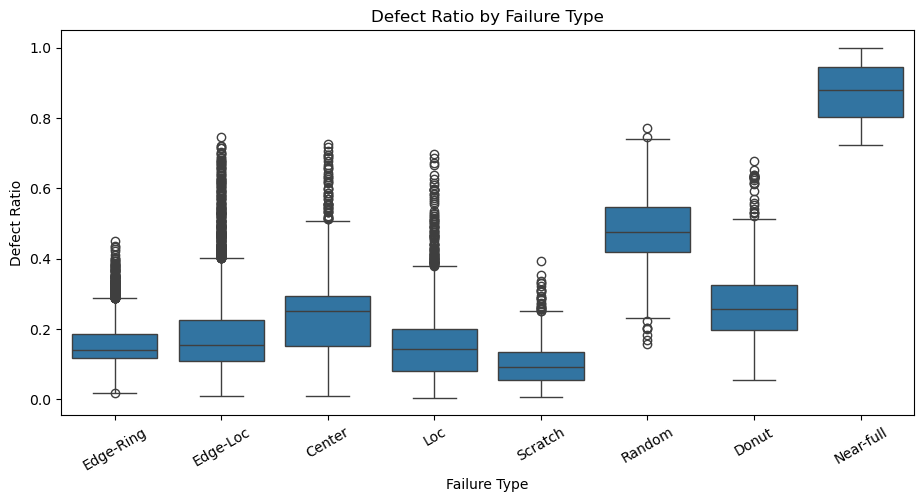

In [9]:
import seaborn as sns

plt.figure(figsize=(11, 5))

sns.boxplot(
    data=df,
    x='failureType_clean',
    y='defect_ratio',
    order=df['failureType_clean'].value_counts().index
)

plt.xticks(rotation=30)
plt.title('Defect Ratio by Failure Type')
plt.xlabel('Failure Type')
plt.ylabel('Defect Ratio')
plt.show()

박스플롯은 데이터의 중앙값, 사분위 범위 및 이상치를 확인할 수 있는 그래프입니다.

**Q12.**

평균 불량률이 가장 높은 유형과 가장 낮은 유형을 찾아보세요.

**답변:**

실제 데이터의 평균 불량률은 **Near-full이 약 0.876908(87.69%)로 가장 높고**, **Scratch가 약 0.100583(10.06%)로 가장 낮습니다**. 이는 유형별 평균이며, 해당 유형의 모든 웨이퍼가 같은 불량률을 갖는다는 뜻은 아닙니다.

**Q13.** 필수 기록

서로 다른 불량 유형이 비슷한 불량률을 가지는 경우가 있나요? 그렇다면 불량률 하나만으로 두 유형을 구분할 수 있을까요?

**답변:**

네. **Edge-Ring의 평균 불량률은 약 15.13%, Loc는 약 15.00%**로 매우 비슷하며, 박스플롯에서도 분포가 겹칩니다. 따라서 불량률 하나만으로 두 유형을 안정적으로 구분하기는 어렵습니다. 불량이 가장자리에 집중되는지, 한곳에 모이는지 등 위치와 모양을 나타내는 특성을 추가해야 합니다.

**Q14.**

같은 불량 유형 안에서도 불량률이 크게 달라지는 경우가 있나요? 그래프를 근거로 설명해 보세요.

**답변:**

네. 예를 들어 **Loc**의 불량률은 약 **0.52%부터 69.76%**까지 분포하며, 중간 50%의 데이터도 약 **8.19%~20.08%**에 걸쳐 있습니다. 박스플롯에서 상자의 폭이 세로 방향으로 퍼져 있고 높은 불량률의 이상치도 보입니다. 같은 `Loc` 라벨이어도 불량 영역의 크기와 불량 칩 수가 달라 불량률이 크게 달라질 수 있습니다.

ACTIVITY C

## 불량이 발생한 위치를 특성으로 만들기

### 1. 불량의 개수만으로 충분할까?

불량률이 같아도 불량이 발생한 위치는 다를 수 있습니다. 예를 들어 불량률이 20%인 두 웨이퍼가 있다고 가정해 봅시다. 웨이퍼 A는 중앙에, 웨이퍼 B는 가장자리에 불량이 집중되어 있습니다. 두 웨이퍼의 불량률은 같지만 불량 패턴은 다릅니다.

따라서 불량 칩의 개수뿐 아니라 **어느 위치에서 불량이 발생했는가**를 특성으로 표현할 필요가 있습니다.

### 2. 가장자리 영역을 정의하기

가장자리 불량률을 구하려면 먼저 웨이퍼의 어느 부분을 가장자리로 볼 것인지 결정해야 합니다. 이번 실습에서는 계산을 단순화하기 위해 다음 기준을 사용합니다.

1. 유효 칩의 위치를 이용해 웨이퍼의 중심을 구합니다.
2. 중심에서 각 칩까지의 거리를 계산합니다.
3. 중심에서 가장 먼 유효 칩까지의 거리를 기준으로, 그 거리의 80% 이상인 영역을 가장자리로 정의합니다.

**영역 정의에 대한 주의**

이는 교육용으로 사용하는 단순화된 기준입니다. 실제 웨이퍼의 외곽을 정확하게 정의하는 방식과는 다를 수 있습니다.

In [11]:
def edge_defect_ratio(wafer_map):
    wafer_map = np.asarray(wafer_map)

    valid = wafer_map != 0
    defect = wafer_map == 2

    if not np.any(valid):
        return 0.0

    y, x = np.indices(wafer_map.shape)

    # 유효 칩을 기준으로 중심 계산
    cy = y[valid].mean()
    cx = x[valid].mean()

    # 중심에서 각 칩까지의 거리
    distance = np.sqrt((y - cy)**2 + (x - cx)**2)

    # 유효 칩 중 중심에서 가장 먼 거리
    max_distance = distance[valid].max()

    # 외곽 20% 영역을 가장자리로 정의
    edge = valid & (distance >= max_distance * 0.8)

    edge_count = np.sum(edge)

    if edge_count == 0:
        return 0.0

    edge_defect_count = np.sum(defect & edge)

    return edge_defect_count / edge_count

이 함수는 가장자리로 정의한 **유효 칩 중 불량 칩의 비율**을 계산합니다. 전체 불량 중 가장자리 불량이 차지하는 비율과는 다릅니다.

**Q15.**

`valid`, `defect`, `edge` 변수는 각각 어떤 칩의 위치를 나타내나요?

**답변:**

- `valid`: 값이 `0`이 아닌 **유효 칩의 위치**입니다.
- `defect`: 값이 `2`인 **불량 칩의 위치**입니다.
- `edge`: 유효 칩이면서 중심으로부터의 거리가 `max_distance × 0.8` 이상인 **가장자리로 정의한 칩의 위치**입니다.

모두 원본 배열과 같은 크기의 불리언 배열이며, `defect & edge`로 가장자리 불량 칩만 선택할 수 있습니다.

**Q16.** 필수 기록

`max_distance * 0.8`에서 `0.8`을 `0.6`으로 변경하면 가장자리로 선택되는 영역은 어떻게 달라질까요?

**답변:**

선택 기준이 최대 거리의 80%에서 60%로 낮아지므로, **기존 가장자리 영역에 더해 안쪽 칩까지 선택되어 영역이 넓어집니다**. 유효 칩만 선택한다는 조건은 같습니다.

첫 번째 웨이퍼에서는 선택되는 칩이 **536개에서 1,040개로 증가**합니다. 거리의 비율을 바꾸는 것이므로 가장자리 칩의 개수나 면적이 단순히 20%에서 40%가 된다는 뜻은 아닙니다.

**Q17.** 필수 기록

가장자리 영역을 정의하는 기준이 바뀌면 계산된 특성값도 달라질까요? 그 이유를 설명해 보세요?

**답변:**

네. 기준이 바뀌면 선택되는 가장자리 칩의 집합이 달라져 **분모인 가장자리 유효 칩 수와 분자인 가장자리 불량 칩 수가 함께 변합니다**. 새로 포함되는 칩의 불량 비율에 따라 결과가 커질 수도, 작아질 수도 있으며 같을 수도 있습니다.

첫 번째 웨이퍼에서는 기준을 `0.8`에서 `0.6`으로 바꾸면 `60 / 536 ≈ 11.19%`에서 `106 / 1040 ≈ 10.19%`로 낮아집니다.

### 3. 가장자리 영역 확인하기

계산된 영역이 실제로 어떻게 생겼는지 확인해 보겠습니다.

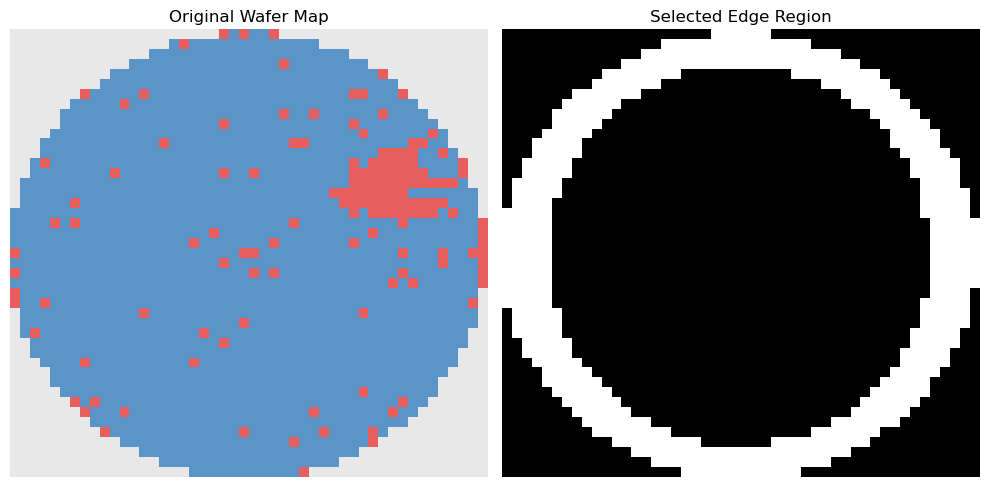

In [12]:
wafer = np.asarray(df.iloc[0]['waferMap'])

valid = wafer != 0
y, x = np.indices(wafer.shape)

cy = y[valid].mean()
cx = x[valid].mean()

distance = np.sqrt((y - cy)**2 + (x - cx)**2)
max_distance = distance[valid].max()

edge = valid & (distance >= max_distance * 0.8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(wafer, cmap=wafer_cmap, vmin=0, vmax=2)
axes[0].set_title('Original Wafer Map')

axes[1].imshow(edge, cmap='gray')
axes[1].set_title('Selected Edge Region')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

두 이미지를 비교해 보세요.

**Q18.**

선택된 가장자리 영역이 실제 웨이퍼맵에서 어떤 부분에 해당하는지 확인해 보세요.

**답변:**

`Selected Edge Region` 그림의 밝은 부분은 **중심에서 비교적 멀리 떨어져 있으면서 실제 유효 칩이 존재하는 바깥쪽 영역**입니다. 검은 부분에는 중앙의 유효 칩과 값이 `0`인 비유효 영역이 함께 포함됩니다. 첫 번째 웨이퍼에서는 이 기준으로 유효 칩 1,683개 중 536개가 가장자리로 선택됩니다. 이 그림은 불량 위치 자체가 아니라, 가장자리 불량률의 분모에 포함할 영역을 보여줍니다.

**Q19.**

이 방법이 모든 웨이퍼맵의 가장자리를 정확하게 표현할 수 있을까요? 한계가 있다면 무엇일까요?

**답변:**

모든 웨이퍼의 실제 가장자리를 정확하게 표현하지는 못합니다. 이 방법은 **유효 칩의 평균 위치에서 얼마나 멀리 떨어져 있는지**를 기준으로 하므로, 실제 외곽선에서의 거리나 일정한 두께를 직접 계산하는 방식과 다릅니다. 길쭉하거나 일부가 잘린 모양, 비대칭 모양에서는 특정 방향만 선택되거나 일부 외곽 칩이 빠질 수 있습니다. 따라서 원본 지도와 선택 영역을 함께 확인하고, 필요하면 실제 외곽선에서의 거리를 이용하는 방법을 검토해야 합니다.

### 4. 새로운 특성을 DataFrame에 추가하기

In [13]:
df['edge_ratio'] = df['waferMap'].apply(edge_defect_ratio)

display(
    df[['failureType_clean',
        'defect_ratio',
        'edge_ratio']].head()
)

,failureType_clean,defect_ratio,edge_ratio
0,Loc,0.086750,0.111940
1,Edge-Loc,0.089024,0.170667
2,Edge-Loc,0.097154,0.173333
3,Edge-Loc,0.109756,0.222667
4,Edge-Loc,0.111382,0.221333


이제 DataFrame에는 두 개의 특성이 추가되었습니다. `defect_ratio`는 전체 유효 칩 중 불량 칩의 비율, `edge_ratio`는 가장자리 유효 칩 중 불량 칩의 비율입니다.

**Q20.** 필수 기록

두 특성은 모두 불량률을 계산하지만, 각각 어떤 정보를 표현하나요?

**답변:**

`defect_ratio`는 **전체 유효 칩 중 불량 칩의 비율**로 웨이퍼 전체의 불량 정도를 나타냅니다. `edge_ratio`는 **가장자리로 선택한 유효 칩 중 불량 칩의 비율**로 외곽 영역의 불량 정도를 나타냅니다.

- 전체 불량률 = 전체 불량 칩 수 / 전체 유효 칩 수
- 가장자리 불량률 = 가장자리 불량 칩 수 / 가장자리 유효 칩 수

`edge_ratio`는 전체 불량 칩 중 가장자리 불량 칩이 차지하는 비율과는 다릅니다.

**Q21.**

`edge_ratio`가 `defect_ratio`보다 훨씬 높다면 이 웨이퍼는 어떤 불량 분포를 가질 가능성이 있을까요?

**답변:**

전체 평균보다 가장자리의 불량 비율이 훨씬 높으므로 **불량이 웨이퍼 외곽에 집중되어 있을 가능성**이 큽니다. `Edge-Ring`이나 `Edge-Loc`와 같은 유형을 예상할 수 있습니다. 다만 가장자리 전체를 둘러싼 고리인지, 가장자리 일부에만 모인 불량인지는 이 두 비율만으로 확정하기 어렵습니다.

ACTIVITY D

## 두 특성으로 불량 패턴을 비교해 보자

### 1. 두 특성의 관계 확인하기

추출한 두 특성을 산점도로 나타내 보겠습니다.

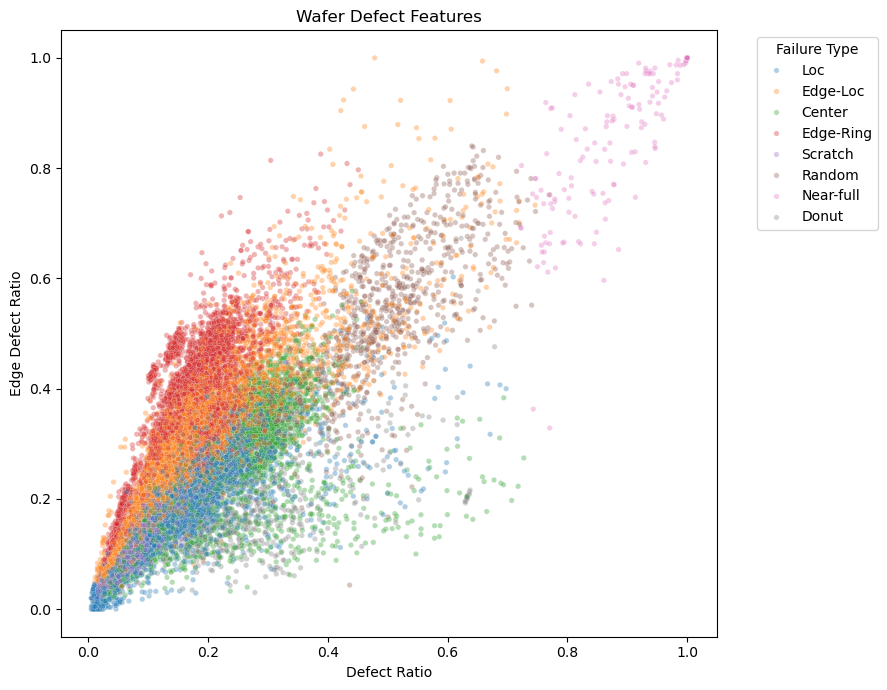

In [14]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=df,
    x='defect_ratio',
    y='edge_ratio',
    hue='failureType_clean',
    alpha=0.35,
    s=15
)

plt.title('Wafer Defect Features')
plt.xlabel('Defect Ratio')
plt.ylabel('Edge Defect Ratio')
plt.legend(
    title='Failure Type',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

산점도의 점 하나는 웨이퍼맵 하나를 의미합니다. 가로축은 전체 불량률, 세로축은 가장자리 불량률이며 색상은 불량 유형을 나타냅니다.

**Q22.**

다른 유형과 비교했을 때 특정 영역에 집중되어 나타나는 불량 유형이 있나요?

**답변:**

네. **Near-full**은 전체 불량률이 약 **72.23%~100%**로 높아 산점도의 오른쪽에 나타나며, 가장자리 불량률도 대체로 높아 오른쪽 위에 모입니다. **Edge-Ring**은 전체 불량률에 비해 가장자리 불량률이 높은 쪽에 많이 나타납니다. 실제 평균은 전체 약 **15.13%**, 가장자리 약 **34.29%**입니다. 다만 `Edge-Loc` 등 다른 유형과 겹치는 점도 있어 완전히 분리되지는 않습니다.

**Q23.** 필수 기록

여러 불량 유형이 겹쳐 있는 영역은 어디인가요? 이 영역에서 두 특성만으로 불량을 구분하기 어려운 이유를 설명해 보세요.

**답변:**

예를 들어 **전체 불량률 약 5~20%, 가장자리 불량률 약 5~30%**인 영역에서는 `Loc`, `Scratch`, `Edge-Loc`, `Edge-Ring`, `Center` 등 여러 유형이 함께 나타납니다. 두 특성은 불량 칩의 개수와 가장자리의 비율을 요약하므로, **선 모양인지, 고리 모양인지, 한곳에 모였는지 같은 세부적인 공간 배치**를 충분히 표현하지 못합니다. 따라서 서로 다른 패턴이 비슷한 두 특성값을 가질 수 있습니다.

**Q24.**

두 특성 중 어느 특성이 불량 유형을 구분하는 데 더 도움이 될 것 같나요? 그래프를 근거로 자신의 생각을 설명해 보세요.

**답변:**

**전체 불량률이 비슷한 유형을 비교할 때는 `edge_ratio`가 추가적인 구분에 도움이 될 것으로 보입니다.** 예를 들어 `Edge-Ring`과 `Loc`의 평균 전체 불량률은 각각 약 **15.13%, 15.00%**로 비슷하지만, 평균 가장자리 불량률은 약 **34.29%, 17.32%**로 차이가 있습니다. 산점도에서도 `Edge-Ring`이 상대적으로 위쪽에 많이 나타납니다.

다만 `Near-full`처럼 불량률 자체가 매우 높은 유형은 `defect_ratio`만으로도 다른 유형과 차이가 잘 드러납니다. 따라서 어느 특성이 항상 더 낫다고 단정하기보다는 **두 특성을 함께 사용하고, 이후 모델 평가로 실제 효과를 확인**해야 합니다.

아직 모델을 학습하지 않았으므로 실제 분류 성능이 어느 정도인지 단정할 수는 없습니다. 지금은 특성값의 분포를 관찰하여 가설을 세우는 단계입니다.

### 2. 특정 불량 유형만 비교하기

전체 불량 유형이 한 그래프에 표시되면 복잡할 수 있습니다. 이번에는 두 유형만 선택해 비교해 보겠습니다.

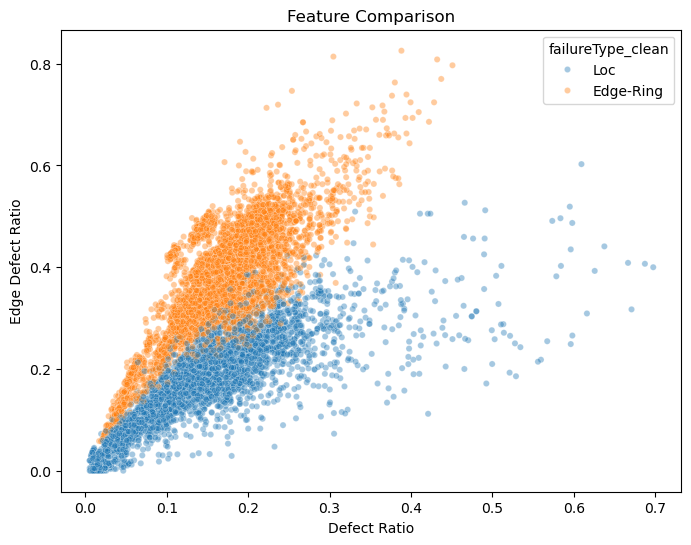

In [15]:
selected_types = ['Edge-Ring', 'Loc']

selected_df = df[
    df['failureType_clean'].isin(selected_types)
]

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=selected_df,
    x='defect_ratio',
    y='edge_ratio',
    hue='failureType_clean',
    alpha=0.4,
    s=20
)

plt.title('Feature Comparison')
plt.xlabel('Defect Ratio')
plt.ylabel('Edge Defect Ratio')
plt.show()

`selected_types`의 값을 바꾸면 다른 불량 유형을 비교할 수 있습니다.

**Q25.**

`selected_types`를 변경하여 구분하기 쉬워 보이는 유형 두 개와 구분하기 어려워 보이는 유형 두 개를 찾아보세요. 각 조합에서 어떤 차이가 나타나는지 설명해 보세요.

**답변:**

**구분하기 쉬워 보이는 조합: `Near-full`과 `Scratch`**

`selected_types = ['Near-full', 'Scratch']`로 바꾸어 비교할 수 있습니다. 이 데이터에서 전체 불량률은 `Near-full`이 약 **72.23~100%**, `Scratch`가 약 **0.71~39.30%**로 서로 겹치지 않습니다. 산점도에서도 `Near-full`은 오른쪽 위에, `Scratch`는 주로 왼쪽 아래에 있어 구분하기 쉽습니다. 이 분리는 현재 데이터에서 관찰한 결과입니다.

**구분하기 어려워 보이는 조합: `Loc`과 `Scratch`**

`selected_types = ['Loc', 'Scratch']`로 바꾸어 비교할 수 있습니다. 두 유형 모두 전체·가장자리 불량률이 낮은 영역에 많은 점이 모여 겹칩니다. 특히 전체 불량률 약 **5~20%**, 가장자리 불량률 약 **5~30%** 부근의 중첩이 큽니다. 점 형태의 국소 불량과 길쭉한 스크래치를 구별하려면 불량 영역의 모양을 나타내는 특성이 더 필요합니다.

### 3. 새로운 특성 아이디어 생각하기

지금까지 불량의 개수와 위치를 이용해 두 가지 특성을 만들었습니다. 하지만 웨이퍼맵에는 더 많은 정보가 있습니다.

| 특성 아이디어 | 확인하려는 정보 | 예상 난이도 |
| --- | --- | --- |
| 상하 불량률 차이 | 위쪽과 아래쪽 중 어디에 불량이 많은가 | 쉬움 |
| 좌우 불량률 차이 | 불량 분포가 좌우로 치우쳐 있는가 | 쉬움 |
| 중앙 영역 불량률 | 중심 부근에 불량이 집중되어 있는가 | 보통 |
| 불량 중심 좌표 | 불량 칩들의 평균 위치는 어디인가 | 보통 |
| 최대 연결 불량 영역 | 서로 연결된 불량 칩이 얼마나 큰 영역을 이루는가 | 어려움 |
| 불량 분포의 방향성 | 불량이 특정 방향으로 길게 이어지는가 | 어려움 |

위의 후보 중 하나를 선택하거나 새로운 특성을 직접 제안해 보세요.

**Q26.** 필수 기록

**나만의 특성 아이디어**
- 특성 이름:
- 어떤 정보를 숫자로 표현하는가?
- 어떤 불량 유형을 구분하는 데 도움이 될 것으로 예상하는가?
- 그렇게 예상한 이유는 무엇인가?
- 웨이퍼맵 배열에서 어떤 값을 계산하면 구현할 수 있을까?

지금은 코드를 완성할 필요가 없습니다.

**답변:**

**특성 아이디어 예시: 중앙 영역 불량률(`center_ratio`)**

- **어떤 정보를 숫자로 표현하나요?** 중심에 가까운 유효 칩 중 불량 칩이 차지하는 비율을 표현합니다.
- **구분에 도움이 될 것으로 예상하는 유형:** `Center`와 `Edge-Ring`입니다.
- **예상 이유:** 중앙에 불량이 모인 패턴과 외곽에 불량이 모인 패턴은 전체 불량률이 비슷해도 중앙 영역의 불량률이 다를 수 있기 때문입니다. 다만 라벨 이름만으로 차이를 보장할 수는 없으므로 실제 분포를 확인해야 합니다.
- **배열에서 계산할 값:** 기존 코드처럼 유효 칩을 기준으로 중심, 각 칩까지의 거리 `distance`, 최대 거리 `max_distance`를 구합니다. `center = valid & (distance <= max_distance * 0.4)`로 중앙 영역을 정하고, `np.sum((wafer_map == 2) & center) / np.sum(center)`를 계산합니다. 중앙 유효 칩이 없으면 `0.0`을 반환합니다.
- **확인할 점:** `0.4`는 제안한 거리 기준이며, 실제 칩의 40%를 선택한다는 뜻은 아닙니다. 영역을 시각화하고 유형별 분포를 비교한 뒤, 이후 실습에서 기존 특성에 추가했을 때 검증 데이터의 성능이 좋아지는지 확인해야 합니다.

이 답변은 **제안한 아이디어**이며, 이 특성의 분류 성능은 아직 검증하지 않았습니다.

다음 실습에서는 자신이 선택한 특성을 실제로 구현하고, 모델 성능에 어떤 영향을 주는지 확인하게 됩니다.

## 미션 01 결과 정리

이번 미션에서는 이미지로 변환하기 전의 웨이퍼맵 배열을 이용해 두 가지 특성을 추출했습니다.

| 특성 | 계산 방법 | 표현하는 정보 |
| --- | --- | --- |
| `defect_ratio` | 불량 칩 수 / 전체 유효 칩 수 | 웨이퍼 전체의 불량 정도 |
| `edge_ratio` | 가장자리 불량 칩 수 / 가장자리 유효 칩 수 | 웨이퍼 외곽 영역의 불량 정도 |

두 특성 모두 불량 칩의 비율을 계산하지만 서로 다른 정보를 표현합니다. 이제 특성을 추가한 DataFrame에서 필요한 열만 별도로 저장해 보겠습니다.

In [16]:
feature_df = df[
    ['failureType_clean', 'defect_ratio', 'edge_ratio']
].copy()

display(feature_df.head())
print(feature_df.shape)

,failureType_clean,defect_ratio,edge_ratio
0,Loc,0.086750,0.111940
1,Edge-Loc,0.089024,0.170667
2,Edge-Loc,0.097154,0.173333
3,Edge-Loc,0.109756,0.222667
4,Edge-Loc,0.111382,0.221333


(25519, 3)


필요하다면 결과를 pickle 파일로 저장할 수 있습니다.

In [17]:
feature_path = data_dir / 'wafer_features.pkl'
feature_df.to_pickle(feature_path)
print("저장 완료:", feature_path)
print("저장한 데이터 크기:", feature_df.shape)

저장 완료: d:\2604340036 - 송성민\2학기\반도체장비AI비전실무\2026-AIVISION_06강\wafer_features.pkl
저장한 데이터 크기: (25519, 3)


**원본 데이터 보관**

저장한 파일에는 숫자 특성과 라벨만 포함됩니다. `waferMap` 배열은 포함되지 않으므로, 개인 특성공학 실습을 위해 `LSWMD_labeled.pkl` 파일도 계속 보관하세요.

### 완료 확인

- [ ] LSWMD_labeled.pkl을 불러오고 데이터 구조를 확인했다.

- [ ] 웨이퍼맵 배열의 값 0, 1, 2의 의미를 이해했다.

- [ ] 전체 불량률을 계산하여 DataFrame에 추가했다.

- [ ] 가장자리 불량률을 계산하여 DataFrame에 추가했다.

- [ ] 두 특성의 분포를 그래프로 비교했다.

- [ ] 자신이 추가하고 싶은 새로운 특성의 아이디어를 작성했다.

### 보고서에 기록할 내용

이번 미션에서 생성한 결과 중 다음 내용을 보관하세요. **모든 Q문항의 답을 보고서에 옮길 필요는 없습니다.**

1. 추출한 두 특성의 이름과 계산 방법
2. 불량 유형별 불량률 분석 결과
3. 두 특성의 관계를 나타낸 산점도와 해석
4. 자신이 선택한 새로운 특성과 선택 이유

**생각 정리**

CNN은 이미지로부터 특징을 학습하고, 특성공학은 사람이 데이터에서 유용한 정보를 선택하거나 만들어 냅니다. 두 방법 중 어느 것이 더 좋은지는 문제와 데이터에 따라 달라집니다. 중요한 것은 예상만으로 판단하지 않고 실제 실험을 통해 검증하는 것입니다.